
# Plano de Experimentação — Agrupamento de Cursos de Engenharia Civil (CPC 2023)

## 1. Objetivo

Investigar se os indicadores do Conceito Preliminar de Curso (CPC) de 2023 permitem identificar perfis acadêmicos interpretáveis entre os cursos de Engenharia Civil avaliados pelo INEP, utilizando técnicas de agrupamento (clustering).

Busca-se também compreender o posicionamento do curso de Engenharia Civil da PUC-Rio em relação aos demais cursos da amostra.

## 2. Base de dados

- Fonte: indicadores do CPC disponibilizados pelo INEP.
- Recorte: cursos de Engenharia Civil, área 5710.
- Amostra prevista: 451 cursos com dados completos.
- Ano de referência: 2023.
- Indicadores originais: ENADE, IDD, proporção de mestres, proporção de doutores, regime de trabalho, organização didático-pedagógica, infraestrutura e oportunidades de ampliação da formação.

A quantidade de cursos e a integridade dos indicadores serão verificadas após o carregamento da base.

## 3. Experimentos previstos

**A0 — Configuração de referência**
- Oito indicadores originais do CPC.
- Padronização dos indicadores.
- K-means com K = 4.

**A1 — Engenharia de características**
- Quatro dimensões: ENADE, IDD, Condições de Formação e Corpo Docente.
- Padronização das dimensões.
- K-means com K = 4.

**A2 — Transformação e redução de dimensionalidade**
- Quatro dimensões derivadas do CPC.
- RobustScaler.
- PCA com duas componentes.
- K-means com K = 2.

## 4. Estratégia de avaliação

Será utilizada uma divisão reproduzível de 80% dos cursos para treinamento e 20% para teste, com `random_state=42`.

As transformações e o K-means serão ajustados exclusivamente com os dados de treinamento. Os cursos de teste serão posteriormente atribuídos aos centróides encontrados.

As principais medidas de avaliação serão:

- Coeficiente de silhueta global e por agrupamento.
- Índice Davies–Bouldin.
- Tamanho dos agrupamentos.
- Distâncias dos cursos aos respectivos centróides.
- Perfis médios dos agrupamentos nos oito indicadores originais.
- Comparação dos perfis com a média da amostra de Engenharia Civil e com o curso da PUC-Rio.

Os resultados também poderão ser reproduzidos na amostra completa para comparação com experimentos exploratórios anteriores, distinguindo-se essas avaliações da análise de treino e teste.

## 5. Critérios de interpretação

A avaliação não será baseada exclusivamente na maximização da silhueta ou na minimização do índice Davies–Bouldin.

Serão considerados a coesão interna, a separação entre grupos, a interpretabilidade dos perfis acadêmicos e a posição da PUC-Rio.

Como as configurações utilizam diferentes representações dos indicadores e diferentes números de grupos, suas métricas não serão tratadas como diretamente equivalentes sem ressalvas.

## 6. Limitações previstas

O CPC é composto por indicadores que podem apresentar correlações e distribuições contínuas, sem necessariamente formar grupos naturalmente separados.

Assim, os agrupamentos serão interpretados como segmentações exploratórias, e não como categorias institucionais previamente existentes.

A divisão treino/teste permitirá avaliar o comportamento das atribuições em novos cursos, mas não constituirá, isoladamente, comprovação de estabilidade ou validade externa dos grupos.

## 7. Resultados esperados

Espera-se produzir:

1. Uma comparação documentada das três configurações de agrupamento.
2. Uma avaliação da coesão e separação dos grupos.
3. Uma caracterização dos perfis acadêmicos encontrados.
4. Uma análise do posicionamento da PUC-Rio.
5. Uma discussão crítica sobre as possibilidades e limitações do agrupamento de cursos a partir dos indicadores do CPC.



In [1]:

import pandas as pd
from pathlib import Path

# Arquivo da base analítica preparada anteriormente
arquivo = Path("base_analitica_1907_cursos.csv")

# Verificar se o arquivo está acessível
if not arquivo.exists():
    print("Arquivo não encontrado na pasta atual.")
    print("Pasta de trabalho:", Path.cwd())
else:
    df = pd.read_csv(arquivo, sep=None, engine="python")

    print("Dimensões da base:", df.shape)
    print("\nColunas disponíveis:")
    print(df.columns.tolist())

    print("\nPrimeiras 3 linhas:")
    display(df.head(3))



Arquivo não encontrado na pasta atual.
Pasta de trabalho: g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026


In [2]:

from pathlib import Path

# Pasta atual do projeto
pasta_projeto = Path.cwd()

print("Pasta do projeto:")
print(pasta_projeto)

# Procurar o arquivo nas subpastas do projeto
arquivos = list(
    pasta_projeto.rglob("base_analitica_1907_cursos.csv")
)

print("\nArquivos encontrados:", len(arquivos))

for i, arquivo in enumerate(arquivos, start=1):
    print(f"{i}. {arquivo}")

# Caso o arquivo não seja encontrado, listar os CSVs disponíveis
if not arquivos:
    print("\nOutros arquivos CSV encontrados:")
    for arquivo in pasta_projeto.rglob("*.csv"):
        print(arquivo)


Pasta do projeto:
g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026

Arquivos encontrados: 1
1. g:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\dados\processados\base_analitica_1907_cursos.csv


In [3]:

import pandas as pd
from pathlib import Path

# Caminho correto da base
arquivo = Path("dados/processados/base_analitica_1907_cursos.csv")

# Carregar o arquivo CSV
df = pd.read_csv(arquivo, sep=None, engine="python")

# Conferir a estrutura
print("Dimensões da base:", df.shape)

print("\nNomes das colunas:")
for coluna in df.columns:
    print(coluna)

print("\nPrimeiras 3 linhas:")
display(df.head(3))

print("\nTotal de valores ausentes:", df.isna().sum().sum())


Dimensões da base: (1907, 35)

Nomes das colunas:
﻿Código da IES
Código do Curso
Modalidade_2017
Area_2017
Modalidade_2019
Area_2019
Modalidade_2023
Area_2023
CPC_2017
CPC_2019
CPC_2023
Enade_2017
IDD_2017
Mestres_2017
Doutores_2017
Regime_Trabalho_2017
Organizacao_Didatica_2017
Infraestrutura_2017
Oportunidades_2017
Enade_2019
IDD_2019
Mestres_2019
Doutores_2019
Regime_Trabalho_2019
Organizacao_Didatica_2019
Infraestrutura_2019
Enade_2023
IDD_2023
Mestres_2023
Doutores_2023
Regime_Trabalho_2023
Organizacao_Didatica_2023
Infraestrutura_2023
Oportunidades_2019
Oportunidades_2023

Primeiras 3 linhas:


,﻿Código da IES,Código do Curso,Modalidade_2017,Area_2017,Modalidade_2019,Area_2019,Modalidade_2023,Area_2023,CPC_2017,CPC_2019,...,Infraestrutura_2019,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2019,Oportunidades_2023
0,1,44,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,2.8917,3.216,...,0.450,4.191,3.488,3.750,2.917,5.0,2.640,1.396,2.476,3.44
1,2,132,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,3.2611,3.220,...,1.335,4.231,4.144,4.922,4.501,5.0,3.111,2.933,3.287,3.92
2,2,1138293,Educação Presencial,21,Educação Presencial,21,Educação Presencial,21,2.9394,3.194,...,0.854,4.194,4.187,4.907,4.519,5.0,3.120,2.866,3.166,3.86



Total de valores ausentes: 0


In [4]:

# Corrigir possíveis caracteres invisíveis nos nomes das colunas
df.columns = df.columns.str.replace("\ufeff", "", regex=False).str.strip()

# Indicadores do CPC 2023
indicadores_2023 = [
    "Enade_2023",
    "IDD_2023",
    "Mestres_2023",
    "Doutores_2023",
    "Regime_Trabalho_2023",
    "Organizacao_Didatica_2023",
    "Infraestrutura_2023",
    "Oportunidades_2023"
]

# Conferir se todas as colunas necessárias existem
colunas_necessarias = [
    "Código da IES",
    "Código do Curso",
    "Area_2023"
] + indicadores_2023

faltantes = [
    coluna for coluna in colunas_necessarias
    if coluna not in df.columns
]

if faltantes:
    raise ValueError(f"Colunas não encontradas: {faltantes}")

# Selecionar os cursos de Engenharia Civil (área 5710)
df_civil = df[
    pd.to_numeric(df["Area_2023"], errors="coerce") == 5710
].copy()

print("Total de cursos de Engenharia Civil:", len(df_civil))

print("\nValores ausentes nos oito indicadores:")
print(df_civil[indicadores_2023].isna().sum())

# Identificar o curso da PUC-Rio
puc_civil = df_civil[
    pd.to_numeric(
        df_civil["Código do Curso"], errors="coerce"
    ) == 29445
]

print("\nRegistros da Engenharia Civil da PUC-Rio:", len(puc_civil))

if not puc_civil.empty:
    display(
        puc_civil[
            ["Código da IES", "Código do Curso"] + indicadores_2023
        ]
    )


Total de cursos de Engenharia Civil: 451

Valores ausentes nos oito indicadores:
Enade_2023                   0
IDD_2023                     0
Mestres_2023                 0
Doutores_2023                0
Regime_Trabalho_2023         0
Organizacao_Didatica_2023    0
Infraestrutura_2023          0
Oportunidades_2023           0
dtype: int64

Registros da Engenharia Civil da PUC-Rio: 1


,Código da IES,Código do Curso,Enade_2023,IDD_2023,Mestres_2023,Doutores_2023,Regime_Trabalho_2023,Organizacao_Didatica_2023,Infraestrutura_2023,Oportunidades_2023
435,528,29445,3.93,3.827,4.315,4.13,2.464,2.934,3.837,3.807


In [5]:

# Corrigir o caractere invisível (BOM) nos nomes das colunas
df.columns = df.columns.str.replace("\ufeff", "", regex=False).str.strip()

# Oito indicadores do CPC 2023
indicadores_2023 = [
    "Enade_2023",
    "IDD_2023",
    "Mestres_2023",
    "Doutores_2023",
    "Regime_Trabalho_2023",
    "Organizacao_Didatica_2023",
    "Infraestrutura_2023",
    "Oportunidades_2023"
]

# Selecionar Engenharia Civil (área 5710)
df_civil = df[
    pd.to_numeric(df["Area_2023"], errors="coerce") == 5710
].copy()

# Localizar o curso da PUC-Rio
puc_civil = df_civil[
    pd.to_numeric(df_civil["Código do Curso"], errors="coerce") == 29445
]

print("Cursos de Engenharia Civil:", len(df_civil))
print("Valores ausentes nos indicadores:",
      df_civil[indicadores_2023].isna().sum().sum())
print("Registros da PUC-Rio:", len(puc_civil))

if not puc_civil.empty:
    print("Código da IES:",
          puc_civil["Código da IES"].iloc[0])


Cursos de Engenharia Civil: 451
Valores ausentes nos indicadores: 0
Registros da PUC-Rio: 1
Código da IES: 528


In [6]:

from sklearn.model_selection import train_test_split

# Separar os índices dos cursos, preservando todas as colunas
df_treino, df_teste = train_test_split(
    df_civil,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

# Conferir a divisão
print("Total de cursos:", len(df_civil))
print("Cursos de treinamento:", len(df_treino))
print("Cursos de teste:", len(df_teste))

# Verificar em qual conjunto ficou a PUC-Rio
puc_treino = (
    pd.to_numeric(
        df_treino["Código do Curso"], errors="coerce"
    ) == 29445
).any()

puc_teste = (
    pd.to_numeric(
        df_teste["Código do Curso"], errors="coerce"
    ) == 29445
).any()

print("\nPUC-Rio no treinamento:", puc_treino)
print("PUC-Rio no teste:", puc_teste)


Total de cursos: 451
Cursos de treinamento: 360
Cursos de teste: 91

PUC-Rio no treinamento: True
PUC-Rio no teste: False


In [7]:

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score
)

# 1. Selecionar os oito indicadores
X_treino_A0 = df_treino[indicadores_2023].copy()
X_teste_A0 = df_teste[indicadores_2023].copy()

# 2. Padronização: ajustar somente no treinamento
scaler_A0 = StandardScaler()

X_treino_A0_pad = scaler_A0.fit_transform(X_treino_A0)
X_teste_A0_pad = scaler_A0.transform(X_teste_A0)

# 3. Ajustar o K-means somente no treinamento
modelo_A0 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

grupos_treino_A0 = modelo_A0.fit_predict(X_treino_A0_pad)

# 4. Atribuir os cursos de teste aos centróides aprendidos
grupos_teste_A0 = modelo_A0.predict(X_teste_A0_pad)

# 5. Calcular as métricas
sil_treino_A0 = silhouette_score(
    X_treino_A0_pad, grupos_treino_A0
)

sil_teste_A0 = silhouette_score(
    X_teste_A0_pad, grupos_teste_A0
)

db_treino_A0 = davies_bouldin_score(
    X_treino_A0_pad, grupos_treino_A0
)

db_teste_A0 = davies_bouldin_score(
    X_teste_A0_pad, grupos_teste_A0
)

# 6. Apresentar os resultados
print("EXPERIMENTO A0 — 8 indicadores, K=4")
print("-" * 42)

print(f"Silhueta treino: {sil_treino_A0:.4f}")
print(f"Silhueta teste:  {sil_teste_A0:.4f}")

print(f"Davies–Bouldin treino: {db_treino_A0:.4f}")
print(f"Davies–Bouldin teste:  {db_teste_A0:.4f}")

print("\nTamanho dos grupos no treinamento:")
print(pd.Series(grupos_treino_A0).value_counts().sort_index())

print("\nTamanho dos grupos no teste:")
print(pd.Series(grupos_teste_A0).value_counts().sort_index())


EXPERIMENTO A0 — 8 indicadores, K=4
------------------------------------------
Silhueta treino: 0.2686
Silhueta teste:  0.2542
Davies–Bouldin treino: 1.3171
Davies–Bouldin teste:  1.1813

Tamanho dos grupos no treinamento:
0     62
1     75
2    110
3    113
Name: count, dtype: int64

Tamanho dos grupos no teste:
0    22
1    17
2    25
3    27
Name: count, dtype: int64


In [8]:

# Criar as quatro dimensões do CPC
def criar_dimensoes_cpc(base):
    resultado = pd.DataFrame(index=base.index)

    resultado["ENADE"] = base["Enade_2023"]
    resultado["IDD"] = base["IDD_2023"]

    resultado["Condicoes_Formacao"] = (
        7.5 * base["Organizacao_Didatica_2023"]
        + 5.0 * base["Infraestrutura_2023"]
        + 2.5 * base["Oportunidades_2023"]
    ) / 15.0

    resultado["Corpo_Docente"] = (
        7.5 * base["Mestres_2023"]
        + 15.0 * base["Doutores_2023"]
        + 7.5 * base["Regime_Trabalho_2023"]
    ) / 30.0

    return resultado


# 1. Construir as dimensões
X_treino_A1 = criar_dimensoes_cpc(df_treino)
X_teste_A1 = criar_dimensoes_cpc(df_teste)

# 2. Padronizar somente com os dados de treinamento
scaler_A1 = StandardScaler()

X_treino_A1_pad = scaler_A1.fit_transform(X_treino_A1)
X_teste_A1_pad = scaler_A1.transform(X_teste_A1)

# 3. Ajustar K-means
modelo_A1 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

grupos_treino_A1 = modelo_A1.fit_predict(X_treino_A1_pad)
grupos_teste_A1 = modelo_A1.predict(X_teste_A1_pad)

# 4. Calcular as métricas
sil_treino_A1 = silhouette_score(
    X_treino_A1_pad, grupos_treino_A1
)

sil_teste_A1 = silhouette_score(
    X_teste_A1_pad, grupos_teste_A1
)

db_treino_A1 = davies_bouldin_score(
    X_treino_A1_pad, grupos_treino_A1
)

db_teste_A1 = davies_bouldin_score(
    X_teste_A1_pad, grupos_teste_A1
)

# 5. Apresentar os resultados
print("EXPERIMENTO A1 — FE-CPC4, K=4")
print("-" * 42)

print(f"Silhueta treino: {sil_treino_A1:.4f}")
print(f"Silhueta teste:  {sil_teste_A1:.4f}")

print(f"Davies–Bouldin treino: {db_treino_A1:.4f}")
print(f"Davies–Bouldin teste:  {db_teste_A1:.4f}")

print("\nTamanho dos grupos no treinamento:")
print(pd.Series(grupos_treino_A1).value_counts().sort_index())

print("\nTamanho dos grupos no teste:")
print(pd.Series(grupos_teste_A1).value_counts().sort_index())


EXPERIMENTO A1 — FE-CPC4, K=4
------------------------------------------
Silhueta treino: 0.2996
Silhueta teste:  0.3098
Davies–Bouldin treino: 1.1199
Davies–Bouldin teste:  1.0416

Tamanho dos grupos no treinamento:
0     68
1    107
2     77
3    108
Name: count, dtype: int64

Tamanho dos grupos no teste:
0    22
1    22
2    19
3    28
Name: count, dtype: int64


In [9]:

from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA

# 1. Utilizar as quatro dimensões já criadas no A1
X_treino_A2 = X_treino_A1.copy()
X_teste_A2 = X_teste_A1.copy()

# 2. Ajustar RobustScaler somente no treinamento
scaler_A2 = RobustScaler()

X_treino_A2_rob = scaler_A2.fit_transform(X_treino_A2)
X_teste_A2_rob = scaler_A2.transform(X_teste_A2)

# 3. Ajustar PCA somente no treinamento
pca_A2 = PCA(n_components=2)

X_treino_A2_pca = pca_A2.fit_transform(X_treino_A2_rob)
X_teste_A2_pca = pca_A2.transform(X_teste_A2_rob)

# 4. Ajustar K-means somente no treinamento
modelo_A2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=20
)

grupos_treino_A2 = modelo_A2.fit_predict(X_treino_A2_pca)
grupos_teste_A2 = modelo_A2.predict(X_teste_A2_pca)

# 5. Calcular métricas no espaço da PCA
sil_treino_A2 = silhouette_score(
    X_treino_A2_pca, grupos_treino_A2
)

sil_teste_A2 = silhouette_score(
    X_teste_A2_pca, grupos_teste_A2
)

db_treino_A2 = davies_bouldin_score(
    X_treino_A2_pca, grupos_treino_A2
)

db_teste_A2 = davies_bouldin_score(
    X_teste_A2_pca, grupos_teste_A2
)

# 6. Apresentar resultados
print("EXPERIMENTO A2 — FE-CPC4 + RobustScaler + PCA, K=2")
print("-" * 55)

print(f"Variância explicada pela PCA: "
      f"{pca_A2.explained_variance_ratio_.sum():.2%}")

print(f"Silhueta treino: {sil_treino_A2:.4f}")
print(f"Silhueta teste:  {sil_teste_A2:.4f}")

print(f"Davies–Bouldin treino: {db_treino_A2:.4f}")
print(f"Davies–Bouldin teste:  {db_teste_A2:.4f}")

print("\nTamanho dos grupos no treinamento:")
print(pd.Series(grupos_treino_A2).value_counts().sort_index())

print("\nTamanho dos grupos no teste:")
print(pd.Series(grupos_teste_A2).value_counts().sort_index())


EXPERIMENTO A2 — FE-CPC4 + RobustScaler + PCA, K=2
-------------------------------------------------------
Variância explicada pela PCA: 78.81%
Silhueta treino: 0.4508
Silhueta teste:  0.5191
Davies–Bouldin treino: 0.8424
Davies–Bouldin teste:  0.7416

Tamanho dos grupos no treinamento:
0    257
1    103
Name: count, dtype: int64

Tamanho dos grupos no teste:
0    66
1    25
Name: count, dtype: int64


In [10]:

import numpy as np
from sklearn.metrics import silhouette_samples

def analisar_coesao_local(X, grupos, modelo, nome):
    # Silhueta individual de cada curso
    sil_individual = silhouette_samples(X, grupos)

    # Distância de cada curso ao centróide de seu grupo
    distancias = np.linalg.norm(
        X - modelo.cluster_centers_[grupos],
        axis=1
    )

    dados = pd.DataFrame({
        "grupo": grupos,
        "silhueta": sil_individual,
        "distancia_centroide": distancias
    })

    resumo = dados.groupby("grupo").agg(
        n_cursos=("grupo", "size"),
        silhueta_media=("silhueta", "mean"),
        percentual_silhueta_negativa=(
            "silhueta",
            lambda x: 100 * (x < 0).mean()
        ),
        distancia_media=("distancia_centroide", "mean"),
        distancia_maxima=("distancia_centroide", "max")
    ).round(4)

    print(f"\nCOESÃO LOCAL — {nome}")
    display(resumo)

    return dados, resumo


# Experimento A0
dados_coesao_A0, resumo_coesao_A0 = analisar_coesao_local(
    X_treino_A0_pad,
    grupos_treino_A0,
    modelo_A0,
    "A0 — 8 indicadores, K=4"
)

# Experimento A1
dados_coesao_A1, resumo_coesao_A1 = analisar_coesao_local(
    X_treino_A1_pad,
    grupos_treino_A1,
    modelo_A1,
    "A1 — 4 dimensões, K=4"
)

# Experimento A2
dados_coesao_A2, resumo_coesao_A2 = analisar_coesao_local(
    X_treino_A2_pca,
    grupos_treino_A2,
    modelo_A2,
    "A2 — PCA, K=2"
)



COESÃO LOCAL — A0 — 8 indicadores, K=4


,n_cursos,silhueta_media,percentual_silhueta_negativa,distancia_media,distancia_maxima
grupo,,,,,
0,62,0.1039,24.1935,2.2986,4.0323
1,75,0.3868,0.0000,1.5884,2.7355
2,110,0.2989,2.7273,1.8350,3.4041
3,113,0.2508,0.8850,1.8244,3.9288



COESÃO LOCAL — A1 — 4 dimensões, K=4


,n_cursos,silhueta_media,percentual_silhueta_negativa,distancia_media,distancia_maxima
grupo,,,,,
0,68,0.2243,1.4706,1.2321,2.4783
1,107,0.2504,0.0000,1.2251,2.2292
2,77,0.4466,0.0000,1.1481,2.3872
3,108,0.2910,0.0000,1.1307,2.6221



COESÃO LOCAL — A2 — PCA, K=2


,n_cursos,silhueta_media,percentual_silhueta_negativa,distancia_media,distancia_maxima
grupo,,,,,
0,257,0.4565,0.3891,0.8050,1.9888
1,103,0.4367,0.0000,0.8116,2.0150


In [11]:

# Função para caracterizar os grupos na escala original do CPC
def comparar_perfis(grupos, nome_experimento):
    base = df_treino[indicadores_2023].copy()
    base["Grupo"] = grupos

    # Média dos indicadores originais em cada grupo
    perfis = base.groupby("Grupo")[indicadores_2023].mean()

    # Média dos 451 cursos de Engenharia Civil
    media_amostra = df_civil[indicadores_2023].mean()

    # Indicadores da PUC-Rio
    perfil_puc = puc_civil[indicadores_2023].iloc[0]

    # Tabela comparativa
    tabela = perfis.T.copy()
    tabela["Média da amostra (451)"] = media_amostra
    tabela["PUC-Rio"] = perfil_puc

    # Identificar grupo da PUC-Rio no treinamento
    posicao_puc = df_treino.index.get_loc(puc_civil.index[0])
    grupo_puc = grupos[posicao_puc]

    print(f"\n{nome_experimento}")
    print(f"Grupo da PUC-Rio: {grupo_puc}")
    display(tabela.round(3))

    return tabela, grupo_puc


perfis_A0, grupo_puc_A0 = comparar_perfis(
    grupos_treino_A0, "A0 — 8 indicadores"
)

perfis_A1, grupo_puc_A1 = comparar_perfis(
    grupos_treino_A1, "A1 — 4 dimensões"
)

perfis_A2, grupo_puc_A2 = comparar_perfis(
    grupos_treino_A2, "A2 — PCA"
)



A0 — 8 indicadores
Grupo da PUC-Rio: 1


Grupo,0,1,2,3,Média da amostra (451),PUC-Rio
Enade_2023,2.090,3.875,2.267,1.829,2.407,3.930
IDD_2023,2.082,3.760,2.336,1.688,2.371,3.827
Mestres_2023,2.564,4.644,4.546,4.398,4.130,4.315
Doutores_2023,1.261,3.738,2.647,3.101,2.767,4.130
Regime_Trabalho_2023,2.794,4.913,4.084,4.268,4.051,2.464
Organizacao_Didatica_2023,3.089,2.359,4.268,2.366,3.057,2.934
Infraestrutura_2023,3.177,2.538,4.442,2.449,3.192,3.837
Oportunidades_2023,2.785,2.990,4.214,2.120,3.036,3.807



A1 — 4 dimensões
Grupo da PUC-Rio: 2


Grupo,0,1,2,3,Média da amostra (451),PUC-Rio
Enade_2023,1.973,2.295,3.884,1.828,2.407,3.930
IDD_2023,1.906,2.385,3.774,1.698,2.371,3.827
Mestres_2023,2.725,4.457,4.653,4.480,4.130,4.315
Doutores_2023,1.233,2.610,3.699,3.261,2.767,4.130
Regime_Trabalho_2023,2.918,4.041,4.920,4.292,4.051,2.464
Organizacao_Didatica_2023,2.947,4.285,2.416,2.411,3.057,2.934
Infraestrutura_2023,3.018,4.448,2.602,2.512,3.192,3.837
Oportunidades_2023,2.643,4.199,3.024,2.204,3.036,3.807



A2 — PCA
Grupo da PUC-Rio: 1


Grupo,0,1,Média da amostra (451),PUC-Rio
Enade_2023,1.945,3.654,2.407,3.930
IDD_2023,1.893,3.615,2.371,3.827
Mestres_2023,4.007,4.607,4.130,4.315
Doutores_2023,2.486,3.508,2.767,4.130
Regime_Trabalho_2023,3.833,4.738,4.051,2.464
Organizacao_Didatica_2023,3.191,2.770,3.057,2.934
Infraestrutura_2023,3.301,2.955,3.192,3.837
Oportunidades_2023,2.988,3.224,3.036,3.807


In [12]:

import numpy as np

def posicao_puc_no_grupo(X, grupos, modelo, nome):
    # Localizar a PUC-Rio no conjunto de treinamento
    pos_puc = df_treino.index.get_loc(puc_civil.index[0])
    grupo_puc = grupos[pos_puc]

    # Distâncias dos cursos aos respectivos centróides
    distancias = np.linalg.norm(
        X - modelo.cluster_centers_[grupos],
        axis=1
    )

    # Distância da PUC-Rio
    distancia_puc = distancias[pos_puc]

    # Distâncias dos cursos pertencentes ao mesmo grupo
    distancias_grupo = distancias[grupos == grupo_puc]

    # Posição relativa da PUC-Rio
    percentil = 100 * np.mean(
        distancias_grupo <= distancia_puc
    )

    print(f"\nEXPERIMENTO {nome}")
    print(f"Grupo da PUC-Rio: {grupo_puc}")
    print(f"Cursos no grupo: {len(distancias_grupo)}")
    print(f"Distância da PUC-Rio: {distancia_puc:.4f}")
    print(f"Distância média do grupo: {distancias_grupo.mean():.4f}")
    print(f"Mediana das distâncias: {np.median(distancias_grupo):.4f}")
    print(f"Percentil da PUC-Rio: {percentil:.1f}%")


posicao_puc_no_grupo(
    X_treino_A0_pad,
    grupos_treino_A0,
    modelo_A0,
    "A0"
)

posicao_puc_no_grupo(
    X_treino_A1_pad,
    grupos_treino_A1,
    modelo_A1,
    "A1"
)

posicao_puc_no_grupo(
    X_treino_A2_pca,
    grupos_treino_A2,
    modelo_A2,
    "A2"
)



EXPERIMENTO A0
Grupo da PUC-Rio: 1
Cursos no grupo: 75
Distância da PUC-Rio: 2.5881
Distância média do grupo: 1.5884
Mediana das distâncias: 1.5063
Percentil da PUC-Rio: 96.0%

EXPERIMENTO A1
Grupo da PUC-Rio: 2
Cursos no grupo: 77
Distância da PUC-Rio: 0.9201
Distância média do grupo: 1.1481
Mediana das distâncias: 1.1352
Percentil da PUC-Rio: 31.2%

EXPERIMENTO A2
Grupo da PUC-Rio: 1
Cursos no grupo: 103
Distância da PUC-Rio: 0.4296
Distância média do grupo: 0.8116
Mediana das distâncias: 0.8012
Percentil da PUC-Rio: 18.4%


In [13]:

# Célula 12 — Contribuição dos indicadores para
# a distância da PUC-Rio ao centróide no A0

pos_puc = df_treino.index.get_loc(puc_civil.index[0])
grupo_puc = grupos_treino_A0[pos_puc]

# Valores padronizados da PUC-Rio e do centróide
valores_puc = X_treino_A0_pad[pos_puc]
centroide = modelo_A0.cluster_centers_[grupo_puc]

# Diferenças quadráticas por indicador
diferencas_quadraticas = (valores_puc - centroide) ** 2

# Participação percentual na distância euclidiana ao quadrado
contribuicoes = (
    100 * diferencas_quadraticas
    / diferencas_quadraticas.sum()
)

tabela_contribuicoes = pd.DataFrame({
    "Indicador": indicadores_2023,
    "Diferença padronizada": valores_puc - centroide,
    "Contribuição (%)": contribuicoes
})

tabela_contribuicoes = (
    tabela_contribuicoes
    .sort_values("Contribuição (%)", ascending=False)
    .reset_index(drop=True)
)

print("A0 — INDICADORES QUE MAIS DISTANCIAM")
print("A PUC-RIO DO CENTRÓIDE DO SEU GRUPO")
print("-" * 48)

display(tabela_contribuicoes.round(3))

print(
    f"\nSoma das contribuições: "
    f"{tabela_contribuicoes['Contribuição (%)'].sum():.1f}%"
)


A0 — INDICADORES QUE MAIS DISTANCIAM
A PUC-RIO DO CENTRÓIDE DO SEU GRUPO
------------------------------------------------


,Indicador,Diferença padronizada,Contribuição (%)
0,Regime_Trabalho_2023,-2.054,62.995
1,Infraestrutura_2023,1.196,21.357
2,Oportunidades_2023,0.746,8.299
3,Organizacao_Didatica_2023,0.540,4.350
4,Doutores_2023,0.316,1.492
5,Mestres_2023,-0.305,1.393
6,IDD_2023,0.066,0.065
7,Enade_2023,0.058,0.049



Soma das contribuições: 100.0%


In [15]:

# Célula 15 — Planejamento das repetições

from sklearn.model_selection import train_test_split
import pandas as pd

sementes = list(range(42, 72))

divisoes_experimentais = []

for semente in sementes:
    indices_treino, indices_teste = train_test_split(
        df_civil.index,
        test_size=0.20,
        random_state=semente,
        shuffle=True
    )

    divisoes_experimentais.append({
        "semente": semente,
        "indices_treino": indices_treino,
        "indices_teste": indices_teste
    })

print("PLANO DE REPETIÇÕES")
print("-" * 35)
print(f"Número de sementes: {len(sementes)}")
print(f"Primeira semente: {sementes[0]}")
print(f"Última semente: {sementes[-1]}")
print(f"Cursos no treinamento: "
      f"{len(divisoes_experimentais[0]['indices_treino'])}")
print(f"Cursos no teste: "
      f"{len(divisoes_experimentais[0]['indices_teste'])}")
print(f"Total de execuções planejadas: "
      f"{len(sementes) * 3}")


PLANO DE REPETIÇÕES
-----------------------------------
Número de sementes: 30
Primeira semente: 42
Última semente: 71
Cursos no treinamento: 360
Cursos no teste: 91
Total de execuções planejadas: 90


In [16]:

from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd

resultados_repeticoes = []

for divisao in divisoes_experimentais:

    semente = divisao["semente"]

    treino = df_civil.loc[divisao["indices_treino"]]
    teste = df_civil.loc[divisao["indices_teste"]]

    # Mesma divisão para os três cenários
    for cenario in ["A0", "A1", "A2"]:

        if cenario == "A0":
            X_treino = treino[indicadores_2023]
            X_teste = teste[indicadores_2023]
            scaler = StandardScaler()
            n_clusters = 4

        elif cenario == "A1":
            X_treino = criar_dimensoes_cpc(treino)
            X_teste = criar_dimensoes_cpc(teste)
            scaler = StandardScaler()
            n_clusters = 4

        else:
            X_treino = criar_dimensoes_cpc(treino)
            X_teste = criar_dimensoes_cpc(teste)
            scaler = RobustScaler()
            n_clusters = 2

        # Ajustar escalonamento somente no treino
        X_treino_proc = scaler.fit_transform(X_treino)
        X_teste_proc = scaler.transform(X_teste)

        # PCA somente no cenário A2
        if cenario == "A2":
            pca = PCA(n_components=2)
            X_treino_proc = pca.fit_transform(X_treino_proc)
            X_teste_proc = pca.transform(X_teste_proc)

        # Ajustar K-means no treinamento
        modelo = KMeans(
            n_clusters=n_clusters,
            random_state=42,
            n_init=20
        )

        grupos_treino = modelo.fit_predict(X_treino_proc)
        grupos_teste = modelo.predict(X_teste_proc)

        # Registrar métricas
        resultados_repeticoes.append({
            "Semente": semente,
            "Cenario": cenario,
            "K": n_clusters,
            "Silhueta_treino": silhouette_score(
                X_treino_proc, grupos_treino
            ),
            "Silhueta_teste": silhouette_score(
                X_teste_proc, grupos_teste
            ),
            "DB_treino": davies_bouldin_score(
                X_treino_proc, grupos_treino
            ),
            "DB_teste": davies_bouldin_score(
                X_teste_proc, grupos_teste
            )
        })

# Construir log completo
log_90 = pd.DataFrame(resultados_repeticoes)

print("LOG DE EXPERIMENTAÇÃO — 90 AVALIAÇÕES")
print("-" * 45)
print(f"Total de registros: {len(log_90)}")

print("\nRegistros por cenário:")
print(log_90["Cenario"].value_counts().sort_index())

print("\nPrimeiras 9 linhas:")
display(log_90.head(9).round(4))

print("\nÚltimas 3 linhas:")
display(log_90.tail(3).round(4))


LOG DE EXPERIMENTAÇÃO — 90 AVALIAÇÕES
---------------------------------------------
Total de registros: 90

Registros por cenário:
Cenario
A0    30
A1    30
A2    30
Name: count, dtype: int64

Primeiras 9 linhas:


,Semente,Cenario,K,Silhueta_treino,Silhueta_teste,DB_treino,DB_teste
0,42,A0,4,0.2686,0.2542,1.3171,1.1813
1,42,A1,4,0.2996,0.3098,1.1199,1.0416
2,42,A2,2,0.4508,0.5191,0.8424,0.7416
3,43,A0,4,0.2724,0.2698,1.2960,1.2480
4,43,A1,4,0.3118,0.2723,1.0889,1.1373
5,43,A2,2,0.4366,0.4361,0.8901,0.9810
6,44,A0,4,0.2761,0.2564,1.2523,1.3408
7,44,A1,4,0.3094,0.2831,1.0810,1.1567
8,44,A2,2,0.4667,0.4277,0.8236,0.9326



Últimas 3 linhas:


,Semente,Cenario,K,Silhueta_treino,Silhueta_teste,DB_treino,DB_teste
87,71,A0,4,0.2744,0.2780,1.2945,1.1682
88,71,A1,4,0.2992,0.3270,1.1159,0.9949
89,71,A2,2,0.4378,0.4781,0.8962,0.7886


In [17]:

# Célula 17 — Resumo estatístico das 30 repetições

metricas = [
    "Silhueta_treino",
    "Silhueta_teste",
    "DB_treino",
    "DB_teste"
]

resumo_30 = (
    log_90
    .groupby("Cenario")[metricas]
    .agg(["mean", "std", "min", "max"])
)

# Facilitar a leitura dos nomes das colunas
resumo_30.columns = [
    f"{metrica}_{estatistica}"
    for metrica, estatistica in resumo_30.columns
]

resumo_30 = resumo_30.round(4)

print("RESUMO ESTATÍSTICO — 30 REPETIÇÕES POR CENÁRIO")
print("-" * 55)

display(resumo_30.T)

# Resumo compacto para a apresentação
resumo_compacto = pd.DataFrame(index=resumo_30.index)

for metrica in metricas:
    resumo_compacto[metrica] = [
        f"{media:.4f} ± {desvio:.4f}"
        for media, desvio in zip(
            resumo_30[f"{metrica}_mean"],
            resumo_30[f"{metrica}_std"]
        )
    ]

print("\nTABELA COMPACTA — MÉDIA ± DESVIO-PADRÃO")
display(resumo_compacto)


RESUMO ESTATÍSTICO — 30 REPETIÇÕES POR CENÁRIO
-------------------------------------------------------


Cenario,A0,A1,A2
Silhueta_treino_mean,0.2720,0.3052,0.4499
Silhueta_treino_std,0.0059,0.0063,0.0112
Silhueta_treino_min,0.2618,0.2921,0.4324
Silhueta_treino_max,0.2850,0.3180,0.4816
Silhueta_teste_mean,0.2628,0.2979,0.4544
Silhueta_teste_std,0.0209,0.0228,0.0348
Silhueta_teste_min,0.2266,0.2467,0.3772
Silhueta_teste_max,0.3126,0.3410,0.5191
DB_treino_mean,1.2846,1.0954,0.8640
DB_treino_std,0.0256,0.0189,0.0316



TABELA COMPACTA — MÉDIA ± DESVIO-PADRÃO


,Silhueta_treino,Silhueta_teste,DB_treino,DB_teste
Cenario,,,,
A0,0.2720 ± 0.0059,0.2628 ± 0.0209,1.2846 ± 0.0256,1.2468 ± 0.0800
A1,0.3052 ± 0.0063,0.2979 ± 0.0228,1.0954 ± 0.0189,1.0908 ± 0.0640
A2,0.4499 ± 0.0112,0.4544 ± 0.0348,0.8640 ± 0.0316,0.8500 ± 0.0838


In [18]:

from pathlib import Path

# Identificar a pasta principal do projeto
pasta_projeto = arquivo.resolve().parent.parent.parent

# Criar pasta para os resultados
pasta_resultados = pasta_projeto / "resultados"
pasta_resultados.mkdir(parents=True, exist_ok=True)

# Arquivos de saída
arquivo_log = pasta_resultados / "log_90_experimentacoes.csv"
arquivo_resumo = pasta_resultados / "resumo_30_repeticoes.csv"

# Exportar log completo
log_90.to_csv(
    arquivo_log,
    index=False,
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

# Exportar resumo estatístico
resumo_30.to_csv(
    arquivo_resumo,
    sep=";",
    decimal=",",
    encoding="utf-8-sig"
)

print("ARQUIVOS EXPORTADOS")
print("-" * 45)
print(f"Log completo: {arquivo_log}")
print(f"Resumo estatístico: {arquivo_resumo}")

print("\nVerificação:")
print(f"Log existe? {arquivo_log.exists()}")
print(f"Resumo existe? {arquivo_resumo.exists()}")


ARQUIVOS EXPORTADOS
---------------------------------------------
Log completo: G:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados\log_90_experimentacoes.csv
Resumo estatístico: G:\Meu Drive\Mestrado _ Eng_Ind\IND2622 - Ciencia de dados para processos de negocios\Trabalho final - CPC (escolhido)\Projeto_CPC_PUC_Rio_2026\resultados\resumo_30_repeticoes.csv

Verificação:
Log existe? True
Resumo existe? True


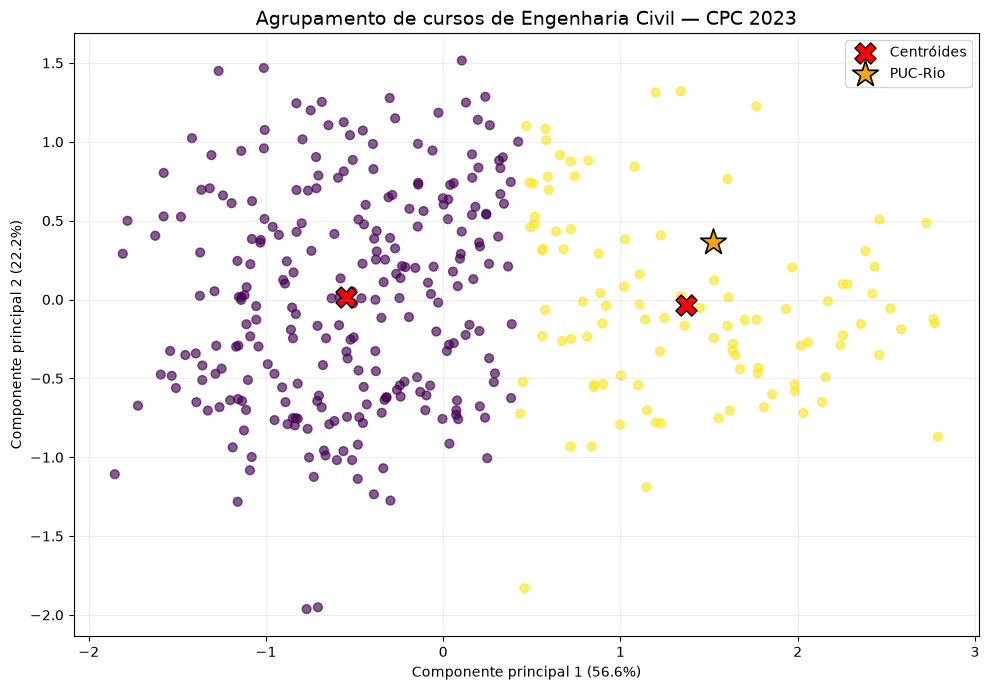

In [19]:

import matplotlib.pyplot as plt
import numpy as np

# Identificar a posição da PUC-Rio no treinamento
pos_puc = df_treino.index.get_loc(puc_civil.index[0])

# Variância explicada por componente
variancia = pca_A2.explained_variance_ratio_ * 100

# Criar gráfico
fig, ax = plt.subplots(figsize=(10, 7))

dispersao = ax.scatter(
    X_treino_A2_pca[:, 0],
    X_treino_A2_pca[:, 1],
    c=grupos_treino_A2,
    cmap="viridis",
    s=40,
    alpha=0.65
)

# Centróides dos grupos
ax.scatter(
    modelo_A2.cluster_centers_[:, 0],
    modelo_A2.cluster_centers_[:, 1],
    marker="X",
    s=230,
    c="red",
    edgecolors="black",
    label="Centróides"
)

# Destacar PUC-Rio
ax.scatter(
    X_treino_A2_pca[pos_puc, 0],
    X_treino_A2_pca[pos_puc, 1],
    marker="*",
    s=380,
    c="orange",
    edgecolors="black",
    linewidths=1.2,
    label="PUC-Rio",
    zorder=5
)

ax.set_title(
    "Agrupamento de cursos de Engenharia Civil — CPC 2023",
    fontsize=14
)

ax.set_xlabel(f"Componente principal 1 ({variancia[0]:.1f}%)")
ax.set_ylabel(f"Componente principal 2 ({variancia[1]:.1f}%)")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


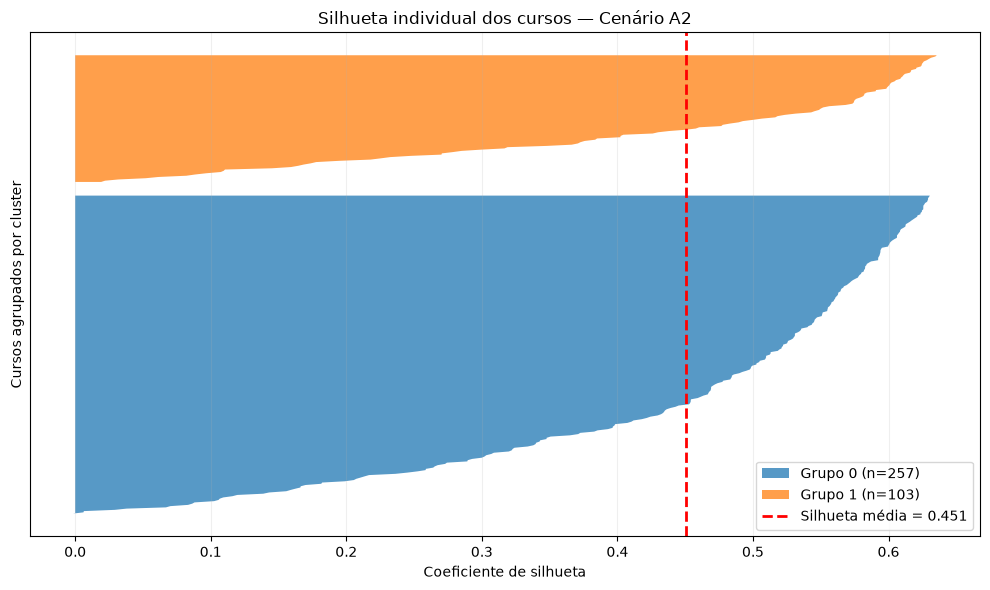

Cursos com silhueta negativa: 1
Percentual com silhueta negativa: 0.28%


In [20]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import silhouette_samples, silhouette_score

silhuetas = silhouette_samples(
    X_treino_A2_pca,
    grupos_treino_A2
)

silhueta_media = silhouette_score(
    X_treino_A2_pca,
    grupos_treino_A2
)

fig, ax = plt.subplots(figsize=(10, 6))

inicio = 10

for grupo in np.unique(grupos_treino_A2):

    valores = np.sort(
        silhuetas[grupos_treino_A2 == grupo]
    )

    quantidade = len(valores)
    fim = inicio + quantidade

    ax.fill_betweenx(
        np.arange(inicio, fim),
        0,
        valores,
        alpha=0.75,
        label=f"Grupo {grupo} (n={quantidade})"
    )

    inicio = fim + 10

ax.axvline(
    silhueta_media,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Silhueta média = {silhueta_media:.3f}"
)

ax.set_title(
    "Silhueta individual dos cursos — Cenário A2"
)

ax.set_xlabel("Coeficiente de silhueta")
ax.set_ylabel("Cursos agrupados por cluster")
ax.set_yticks([])
ax.legend(loc="best")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

print(
    "Cursos com silhueta negativa:",
    int((silhuetas < 0).sum())
)

print(
    "Percentual com silhueta negativa:",
    f"{100 * (silhuetas < 0).mean():.2f}%"
)


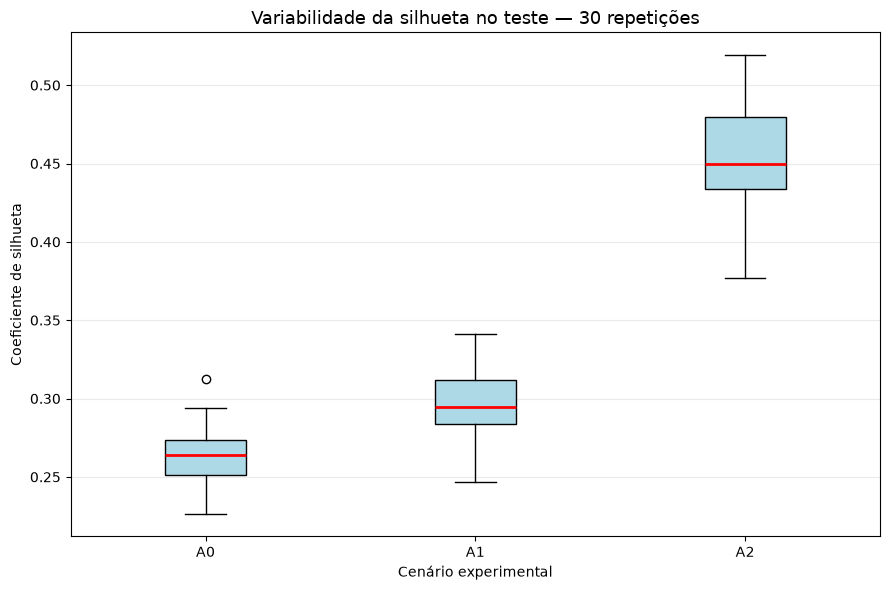

In [21]:

import matplotlib.pyplot as plt

dados_boxplot = [
    log_90.loc[
        log_90["Cenario"] == cenario,
        "Silhueta_teste"
    ].values
    for cenario in ["A0", "A1", "A2"]
]

fig, ax = plt.subplots(figsize=(9, 6))

ax.boxplot(
    dados_boxplot,
    tick_labels=["A0", "A1", "A2"],
    patch_artist=True,
    boxprops={"facecolor": "lightblue"},
    medianprops={"color": "red", "linewidth": 2}
)

ax.set_title(
    "Variabilidade da silhueta no teste — 30 repetições",
    fontsize=13
)
ax.set_xlabel("Cenário experimental")
ax.set_ylabel("Coeficiente de silhueta")

ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()


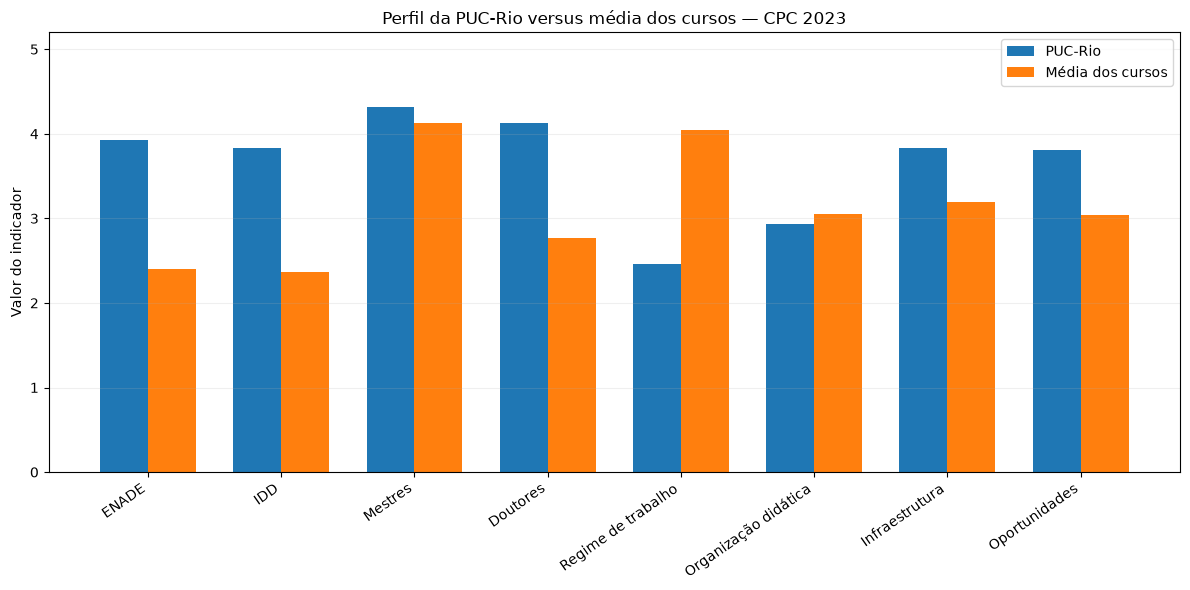

In [22]:

import matplotlib.pyplot as plt
import numpy as np

# Indicadores originais
nomes = [
    "ENADE", "IDD", "Mestres", "Doutores",
    "Regime de trabalho", "Organização didática",
    "Infraestrutura", "Oportunidades"
]

# Médias dos cursos de Engenharia Civil
media_cursos = df_civil[indicadores_2023].mean().values

# Valores da PUC-Rio
valores_puc = puc_civil[indicadores_2023].iloc[0].values

# Posições das barras
posicoes = np.arange(len(nomes))
largura = 0.36

fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    posicoes - largura / 2,
    valores_puc,
    largura,
    label="PUC-Rio"
)

ax.bar(
    posicoes + largura / 2,
    media_cursos,
    largura,
    label="Média dos cursos"
)

ax.set_title(
    "Perfil da PUC-Rio versus média dos cursos — CPC 2023"
)
ax.set_ylabel("Valor do indicador")
ax.set_xticks(posicoes)
ax.set_xticklabels(nomes, rotation=35, ha="right")
ax.set_ylim(0, 5.2)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


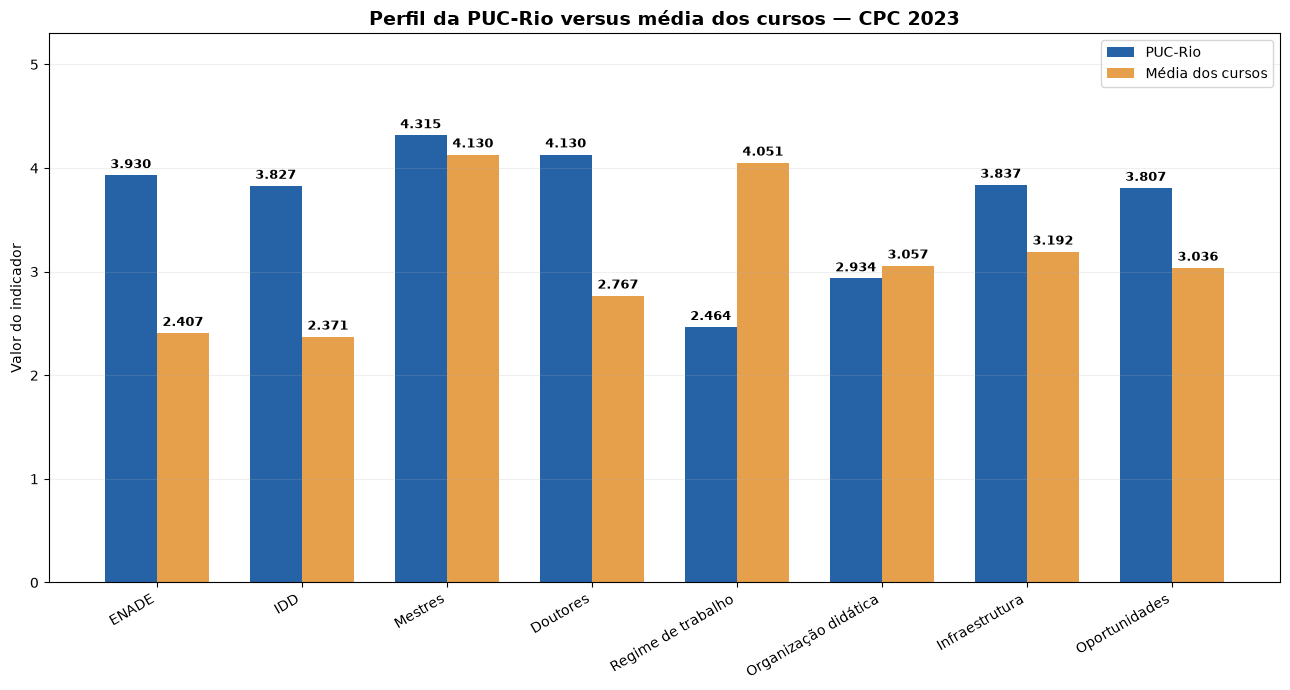

In [23]:

import matplotlib.pyplot as plt
import numpy as np

nomes = [
    "ENADE", "IDD", "Mestres", "Doutores",
    "Regime de trabalho", "Organização didática",
    "Infraestrutura", "Oportunidades"
]

media_cursos = df_civil[indicadores_2023].mean().values
valores_puc = puc_civil[indicadores_2023].iloc[0].values

posicoes = np.arange(len(nomes))
largura = 0.36

fig, ax = plt.subplots(figsize=(13, 7))

barras_puc = ax.bar(
    posicoes - largura / 2,
    valores_puc,
    largura,
    label="PUC-Rio",
    color="#2563A6"
)

barras_media = ax.bar(
    posicoes + largura / 2,
    media_cursos,
    largura,
    label="Média dos cursos",
    color="#E6A04B"
)

# Inserir os valores acima das barras
ax.bar_label(
    barras_puc,
    fmt="%.3f",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

ax.bar_label(
    barras_media,
    fmt="%.3f",
    padding=3,
    fontsize=9,
    fontweight="bold"
)

ax.set_title(
    "Perfil da PUC-Rio versus média dos cursos — CPC 2023",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Valor do indicador")
ax.set_xticks(posicoes)
ax.set_xticklabels(nomes, rotation=30, ha="right")
ax.set_ylim(0, 5.3)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()
